In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate


##  Understanding Predator-Prey Dynamics
### The interaction between predators and prey has been studied for over 100 years in biology, especially through mathematical models. 
### The basic idea is simple:

### Predators eat prey, so prey numbers go down while predator numbers rise.

### As prey become scarce, predators struggle to find food, so predator numbers drop.

### With fewer predators, prey have a chance to rebound, and the cycle repeats.

### This repeating rise and fall is called the canonical predator-prey cycle (also known as the Lotka-Volterra cycle), 
### where prey peak first, then predators, followed by prey hitting a low point, and so on.

## But Nature Isn't Always That Predictable
### Real-world ecosystems don't always follow this neat cycle. Sometimes:

### Predator and prey peak at the same time, or

### Predators peak before prey, or

### The cycles can be reversed or irregular.

### These unusual patterns are not rare — they happen because two major assumptions in the classic models are often not true in nature:

## Critical assumptions of classical models that fall apart:

### Slow Evolution
### Most models assume that prey and predators don't change much genetically over time.
### But in reality, evolution can happen quickly, 
### so different types of prey or predators (with different traits) may exist and shift during the cycle

### Linear Contact Rates
### Classic models assume predators find and eat prey at a constant rate (linear).
### But in truth, predator-prey interactions are often nonlinear
### — it takes time to find, catch, and handle prey, especially as prey density changes.

## What This Lab Explores
### This lab dives into:

### How having multiple types of prey (e.g., some fast-growing, some well-defended) changes dynamics.

### How functional responses (the way predators respond to prey density eg; handling )affect stability (Look at first figure)

### And finally, how individual-based models (simulating each predator and prey) reveal more realistic and complex behaviors.

# Read introduction for 5 min

## Classic predator-prey model

### $$\frac{dN}{dt} = rN(1-N/K) - bNP $$
### $$\frac{dP}{dt} = \epsilon bNP - mP $$
### Note: The conversion rate from prey to predator $c$ in the book is $\epsilon b$ here,

### I wrote it as $\epsilon b$  because I want the *flow* to be clear
### but from now on I will be writing it as c for book equivalence
## This system of differential eqs can be coded up as follows: 

In [5]:
def model_pp(y,t,pars):
    
    dydt = np.zeros(2)
    
    dydt[0] = pars['r']*y[0]*(1-y[0]/pars['K'])-pars['b']*y[0]*y[1]
    dydt[1] = pars['c']*y[0]*y[1]-pars['m']*y[1]
    
    return dydt

### These dynamics lead to a stable balance between predators and prey 
### as long as the prey population at equilibrium (N* ) stays below the carrying capacity (K). 
----
### This happens when predators can survive even if there aren’t many prey around, 
### which depends on the ratio of their death rate (m) to how efficiently they convert prey into growth (c).
----
### This idea is the basis for the first challenge problem.

<div class="alert alert-block alert-warning">
<b>Challenge Problem:  Convergent Predator prey dynamics</b>
    
***

Find critical value of the clearance rate $b$ that allows for predator- prey coexistence and show the dynamics (vs time imo)    

</div>

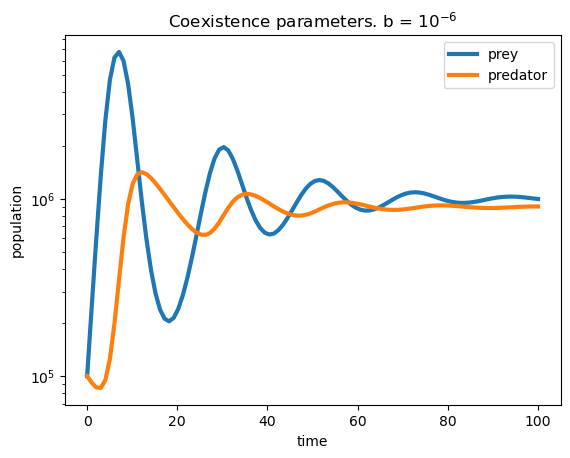

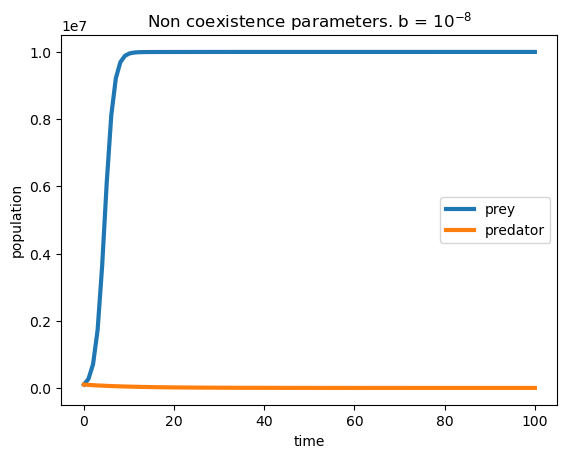

In [41]:
pars={}
pars['r']=1
pars['K']=10**7
pars['eps']=0.1
pars['m']=0.1
pars['T']=100

# Coexistence case
pars['b']=10**-6
pars['c'] = 0.1*pars['b']
t =np.linspace(0,pars['T'],100)
y0=10**5*np.ones(2)
y = integrate.odeint(model_pp,y0,t,args=(pars,))
plt.semilogy(t,y[:,0],linewidth=3, label = 'prey')
plt.semilogy(t,y[:,1],linewidth=3, label = 'predator')
plt.title(r'Coexistence parameters. b = $10^{-6}$')
plt.xlabel('time')
plt.ylabel('population')
plt.legend()
plt.show()


# Failure case
pars['b']=10**-8
pars['c']=0.1*pars['b']
y = integrate.odeint(model_pp,y0,t,args=(pars,))

plt.plot(t,y[:,0],linewidth=3, label = 'prey')
plt.plot(t,y[:,1],linewidth=3, label = 'predator')
plt.title(r'Non coexistence parameters. b = $10^{-8}$')
plt.xlabel('time')
plt.ylabel('population')
plt.legend()
plt.show()



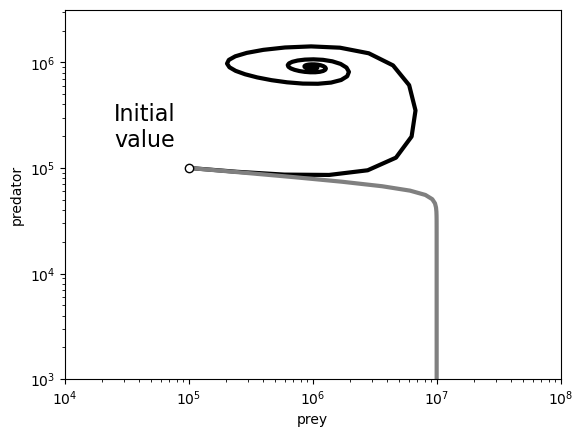

In [9]:
pars={}
pars['r']=1
pars['K']=10**7
pars['eps']=0.1
pars['m']=0.1
pars['T']=100
fig = plt.figure()
ax = fig.gca()

# Coexistence case
pars['b']=10**-6
pars['c'] = 0.1*pars['b']
t =np.linspace(0,pars['T'],100)
y0=10**5*np.ones(2)
y = integrate.odeint(model_pp,y0,t,args=(pars,))
plt.loglog(y[:,0],y[:,1],'k',linewidth=3)

# Failure case
pars['b']=10**-8
pars['c']=0.1*pars['b']
y = integrate.odeint(model_pp,y0,t,args=(pars,))

plt.loglog(y[:,0],y[:,1],color=[0.5,0.5,0.5],linewidth=3)
plt.loglog(y0[0],y0[1],marker='o',markeredgecolor='k',markerfacecolor='w')
plt.xlim(10**4,10**8)
plt.ylim(10**3,10**6.5)
plt.xlabel('prey')
plt.ylabel('predator')
plt.text(10**4.4,10**5.2,'Initial\nvalue',fontsize=16)
plt.show()



## Functional responses: How does the prey --> predator *really* flow take place?

### The standard predator-prey dynamic model given N prey and P predators
### with prey-density limitation and a generalized ‘functional response’ is:

### $$\frac{dN}{dt} = rN(1-N/K) - bf(N)P $$
### $$\frac{dP}{dt} = cf(N)P - mp $$
### Where f(N) replaces N from the original system 
### f(N) denotes the functional response of how the clearance rate of prey by predators scales with prey density ]

### type 1: $f(N) \sim N$, that means predators clear prey linearly with prey density 
---
### type 2 : $f(N) \sim \frac{N}{Q+N}$, that means the rate at which predators clear prey increases as prey increases
### but then slows down eventually (they can’t eat infinitely fast, limited by handling time)
---
### type 3: $f(N) \sim \frac{N^2}{Q^2+N^2}$, clearing rate starts slow when prey are rare (hard to find), 
### then speeds up, and finally levels off like Type 2
---

### Clearly, using different functional response modifies the stability of the coexistence fixed point 

### We will explore a version of the type 2 response: 

### $$\frac{dN}{dt} = rN(1-N/K) - \frac{bN}{1+b\tau N}P $$
### $$\frac{dP}{dt} = \frac{\epsilon bN}{1+b\tau N}P - mp $$

### Where once again $\epsilon b = c$ and $\epsilon$ is the conversion rate of prey biomass to predator biomass
### But this time, there is an effective handling time $\tau$ (eg; how long it takes predators to eat)
### this is called the MacArthur-Rosenzweig model

In [12]:
def pp_dyn_type2(y,t,pars):
    
    N=y[0]
    P=y[1]
    dydt = np.zeros(2)
    dydt[0] = pars['r']*N*(1-N/pars['K'])-pars['b']*N*P/(1+pars['b']*pars['tau']*N)
    dydt[1] = pars['eps']*pars['b']*N*P/(1+pars['b']*pars['tau']*N)-pars['m']*P
    return dydt

## We are going to use this model for the next challenge problem

<div class="alert alert-block alert-warning">
<b>Challenge Problem: From Convergence to Limit Cycles</b>
    

   

</div>

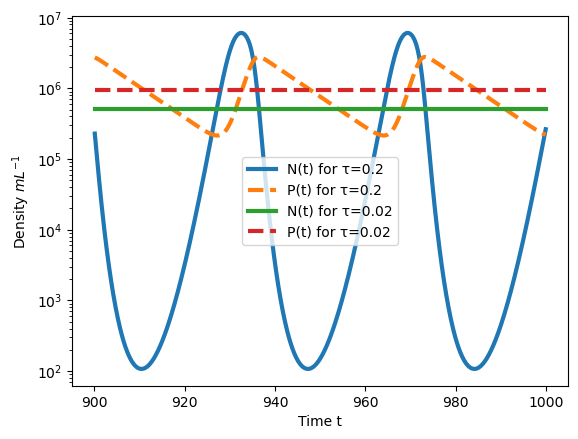

In [43]:

pars = {}
pars['r'] = 1.0
pars['K'] = 1e7
pars['b'] = 1e-6
pars['eps'] = 0.2
pars['m'] = 0.1

# Set up a time array from 0 to 1000 hours with a time step of 0.1
t = np.arange(0, 1000, 0.1)

# Initial conditions for prey and predator populations: both start at 10^5 cells/mL
y0 = 10**5 * np.ones(2)  # [N0, P0] = [10^5, 10^5]

# Limit cycle case 
pars['tau'] = 0.2  # Set tau to 0.2, known to induce limit cycles
z = integrate.odeint(pp_dyn_type2, y0, t, args=(pars,))
tmpi = np.where(t > 900)
plt.plot(t[tmpi], np.transpose(z[tmpi, 0]), linewidth=3, label='N(t) for τ=0.2')
plt.plot(t[tmpi], np.transpose(z[tmpi, 1]),linestyle='--', linewidth=3, label='P(t) for τ=0.2')

# No limit cycles case 
pars['tau'] = 0.02  # Set tau to 0.02, which leads to convergence to fixed point
y = integrate.odeint(pp_dyn_type2, y0, t, args=(pars,))
tmpi = np.where(t > 900)
plt.semilogy(t[tmpi], np.transpose(y[tmpi, 0]), linewidth=3, label='N(t) for τ=0.02')
plt.semilogy(t[tmpi], np.transpose(y[tmpi, 1]), linestyle='--', linewidth=3, label='P(t) for τ=0.02')


plt.xlabel('Time t')
plt.ylabel('Density $mL^{-1}$')

plt.legend()
plt.show()



### Shows how prey (N) and predator (P) populations change over time for two different values of the parameter τ.

### With high τ (0.2), the populations oscillate repeatedly — a behavior known as a limit cycle.

### With low τ (0.02), both populations stabilize at constant values — reaching a fixed point.

### Prey and predator curves are plotted with solid and dashed lines, respectively, and the logarithmic y-axis helps visualize large variations.

### This demonstrates how predator response time (captured by τ) can dramatically alter ecosystem dynamics.



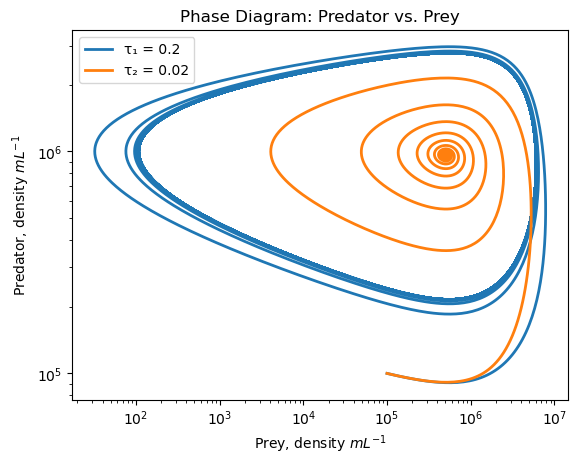

In [17]:

# τ = 0.2 → limit cycles
plt.figure()
plt.loglog(z[:, 0], z[:, 1], linewidth=2, label='τ₁ = 0.2')

# τ = 0.02 → convergence to fixed point
plt.loglog(y[:, 0], y[:, 1],  linewidth=2, label='τ₂ = 0.02')


# Axis labels and legend
plt.xlabel('Prey, density $mL^{-1}$')
plt.ylabel('Predator, density $mL^{-1}$')

plt.legend()

plt.title('Phase Diagram: Predator vs. Prey')
plt.show()


### Plots predator density vs. prey density instead of over time — a snapshot of their relationship across time.

### The blue curve (τ = 0.2) forms a loop, showing that the populations cycle through a repeated trajectory.

### The orange curve (τ = 0.02) spirals into a point, showing convergence to a stable equilibrium.

### Both axes are on a log scale to better display the wide range of population values.

### This plot reveals the structure of system dynamics and helps identify whether the system is oscillating or stabilizing
----

### Up to this point, our models assumed that all prey are identical: same growth, same vulnerability.
### But in real ecosystems, this is rarely true. There are often different types of prey, even if they look similar.

### For example:

### One type might grow quickly, but be easy to catch.

### Another might grow slowly, but have strong defenses against predators.

### Even though it’s hard to tell them apart in the lab (due to limits in genetic tools or hidden traits),
### these differences can significantly change the dynamics of predator-prey systems.

## In this new version of the model:

### $N_1$ = growth-specialist prey

### $N_2$ = defense-specialist prey

### $P$ =  predator

### \begin{align}
\frac{dN_1}{dt} &= r_1 N_1 \left(1 - \frac{N_1 + a_{12} N_2}{K_1} \right) - \frac{c_1 N_1 P}{1 + c_1 N_1 + c_2 N_2} \\
\frac{dN_2}{dt} &= r_2 N_2 \left(1 - \frac{N_2 + a_{21} N_1}{K_2} \right) - \frac{c_2 N_2 P}{1 + c_1 N_1 + c_2 N_2} \\
\frac{dP}{dt} &= \left( \frac{\varepsilon c_1 N_1 + \varepsilon c_2 N_2}{1 + c_1 N_1 + c_2 N_2} \right) P - mP
\end{align} 

### The model equations track how each prey type grows and is eaten, and how predators respond to both types.
### The prey interact with each other (e.g., competing for resources), and the predator feeds on both — but not equally.

### If you run this model, you'll often see "anti-phase dynamics":

### Predators peak right when total prey are lowest, and vice versa.

### Why? Because the balance between the two prey types is shifting rapidly — as predators eat more of one type, the other can take over.
### This creates eco-evolutionary dynamics, where evolution-like changes (in the traits or types of prey) happen on the same time scale as population changes
### I won't go into this too much as this is part of the exploration of the next and final challenge problem for the lab

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Model of eco-evolutionary dynamics</b>
    

   

</div>

In [22]:
def pp_dyn_evo(y, t, pars):
    N1 = y[0]
    N2 = y[1]
    P = y[2]
    N = N1 + N2

    dydt = np.zeros(3)
    Q = pars["tau"]*pars["c1"] * N1 + pars["tau"]*pars["c2"] * N2
    dydt[0] = pars["r1"] * N1 * (1 - N / pars["K1"]) - pars["c1"] * N1 * P / (1 + Q)
    dydt[1] = pars["r2"] * N2 * (1 - N / pars["K2"]) - pars["c2"] * N2 * P / (1 + Q)
    dydt[2] = pars["eps"] * (Q / (1 + Q)) * P - pars["m"] * P

    return dydt


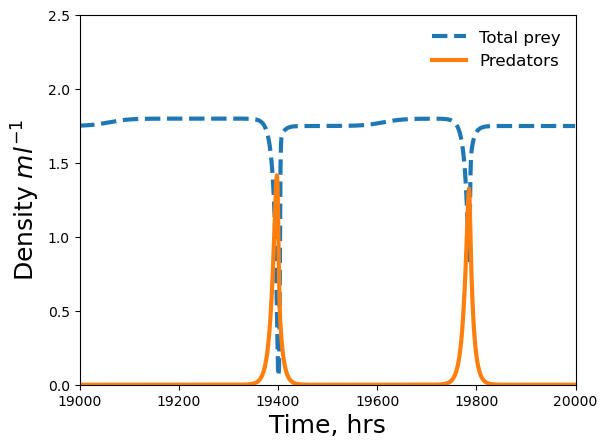

In [23]:
# Parameter Setup 
pars = {}
pars["r1"] = 1.8  
pars["r2"] = 1.75
pars["c1"] = 3  
pars["c2"] = 0.3  
pars["tau"] = 1 
pars["K1"] = 1.8  
pars["K2"] = 1.75  
pars["eps"] = 0.5  
pars["m"] = 0.3  

# Time vector: simulate from t = 0 to 20000 hours (long timescale to observe cycles)
t = np.arange(20000)

# Initial conditions: 
# N1 = 0.13 (prey 1), N2 = 1.35 (prey 2), P = 1.2 (predator)
y0 = np.array([0.13, 1.35, 1.2])

# rtol and hmax control the solver’s precision and maximum time step
y = integrate.odeint(pp_dyn_evo, y0, t, args=(pars,), rtol=10**-7, hmax=1)
# Total prey = N1 + N2 
N = y[:, 0] + y[:, 1]
# Plot total prey
plt.plot(t, N , linewidth=3, linestyle="--")
# Plot predator density over time
plt.plot(t, y[:, 2], linewidth=3)
# Set vertical limits for density
plt.ylim(0, 2.5 )
# Focus in on the last 1000 hours of the simulation
plt.xlim(19000, 20000)
plt.xlabel(r"Time, hrs", fontsize=18)
plt.ylabel(r"Density $ml^{-1}$", fontsize=18)
plt.legend(["Total prey", "Predators"], fontsize=12, loc="upper right", frameon=False)
